# Scores and diagnostics

**Before you trust a score, check that the forecast is well formed, and measure it against the answer key rather than against one noisy future.**

This chapter builds what `Pipeline.test` does with every forecast: the scores, the evaluator that runs the output checks and turns scores into verdicts, intervals that say how sure you can be across many cases, a check of a promise some models make, and fault fixtures that break a correct forecast in known ways. They make up five modules: `metrics`, `statistics`, `diagnostics`, `checks` and `mutations`.

Below we see which score to read, why the error against the answer key can tell two models apart with far fewer cases, what each of the five verdicts means, and which check catches each of eight faults, including two that leave the forecast looking fine.

**Development notebook.** The collapsed cells are the source of those five modules; expand them to edit, then restart the kernel and Run All ([build workflow](README.md#develop-the-package-here)).

In [1]:
#| default_exp metrics

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110, 'font.size': 11,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)

## Scores

Every score is a loss: lower is better. Point scores compare the point forecast, which TimeGym reads as the forecast's mean, with what actually happened or with the answer key. Uncertainty scores compare quantiles or sample paths with what actually happened. These cells write `timegym/metrics.py`.

### Checking the inputs

Every score first refuses what it can't score honestly: an empty array, NaN or infinity, or a forecast shaped differently from what actually happened (quantiles add a level axis at the end, samples a sample axis at the front). A score that is undefined for valid data, such as MASE on a history that never changes, raises `UndefinedMetricError` instead of returning a made-up number.

In [3]:
#| export metrics
from __future__ import annotations
from timegym._internal import positive_int, _real_array, _deprecated

import numpy as np

In [4]:
#| export metrics
class UndefinedMetricError(ValueError):
    """A score is undefined for the supplied, otherwise valid, data."""

In [5]:
#| export metrics
def _array(value, name):
    array = _real_array(value, name)
    if array.ndim == 0 or array.size == 0:
        raise ValueError(f"{name} must be a nonempty array")
    if not np.all(np.isfinite(array)):
        raise ValueError(f"{name} must contain only finite numbers")
    return array

In [6]:
#| export metrics
def _pair(observed, predicted):
    observed = _array(observed, "observed")
    predicted = _array(predicted, "predicted")
    if observed.shape != predicted.shape:
        raise ValueError("observed and predicted must have identical shapes")
    return observed, predicted

In [7]:
#| export metrics
def _ensemble(observed, samples):
    observed = _array(observed, "observed")
    samples = _array(samples, "samples")
    if samples.ndim != observed.ndim + 1 or samples.shape[1:] != observed.shape:
        raise ValueError("samples must have shape (n_samples, *observed.shape)")
    return observed, samples

### Error against what actually happened (`mse`, `mae`)

Squared and absolute error, averaged over every step and series. Squared error rewards the right mean, absolute error the right median. On real data this is the error you have.

In [8]:
#| export metrics
def mse(observed, predicted):
    """Mean squared error over observation coordinates."""
    observed, predicted = _pair(observed, predicted)
    return float(np.mean((observed - predicted) ** 2))

In [9]:
#| export metrics
def mae(observed, predicted):
    """Mean absolute error over observation coordinates."""
    observed, predicted = _pair(observed, predicted)
    return float(np.mean(np.abs(observed - predicted)))

### Error against the answer key (`mean_reference_mse`)

The same squared error, measured against the answer key instead of against what actually happened, so 0 means as good as the answer key. The noise in the one future that happened stays out of it. Averaged over many futures from the same history, the error against what actually happened is this error plus the answer key's own error: the noise no forecaster can remove. It exists only for generated data.

In [10]:
#| export metrics
def mean_reference_mse(reference_mean, predicted):
    """Squared distance from a supplied conditional mean, not generic regret.

    With a valid conditional mean this is the conditional excess squared-error
    risk, averaged over coordinates. It is not realised loss against a future
    observation and is not a reference for other losses.
    """
    return mse(reference_mean, predicted)

### Error scaled by the history (`mase`)

MASE divides the absolute error by the history's average one-step change, so that series on different scales can be compared. The evaluator always uses one-step changes (`seasonality=1`). A history that never changes has nothing to divide by, so MASE raises rather than adding a tiny number.

In [11]:
#| export metrics
def mase(observed, predicted, context, seasonality=1):
    """MASE, scaling each target by its in-context seasonal naive MAE.

    Time is axis zero. A constant target or insufficient history makes the
    aggregate undefined and raises ``UndefinedMetricError``; no epsilon
    denominator or omission of constant targets is silently introduced.
    """
    observed, predicted = _pair(observed, predicted)
    context = _array(context, "context")
    seasonality = positive_int(seasonality, 'seasonality')
    if context.ndim != observed.ndim or context.shape[1:] != observed.shape[1:]:
        raise ValueError("context and observed must have identical non-time dimensions")
    if len(context) <= seasonality:
        raise UndefinedMetricError("MASE needs more context observations than seasonality")
    scale = np.mean(np.abs(context[seasonality:] - context[:-seasonality]), axis=0)
    if np.any(scale == 0):
        raise UndefinedMetricError("MASE is undefined for a zero naive-error denominator")
    return float(np.mean(np.abs(observed - predicted) / scale))

### Quantiles (`pinball`)

Pinball loss scores each quantile by how it is missed: at the 90% level, a value that lands above the quantile costs nine times as much as one the same distance below it. Crossed quantiles are refused.

In [12]:
#| export metrics
def pinball(observed, quantiles, levels):
    """Mean quantile (pinball) loss, without the optional factor of two."""
    observed = _array(observed, "observed")
    quantiles = _array(quantiles, "quantiles")
    levels = _array(levels, "levels")
    if levels.ndim != 1 or np.any((levels <= 0) | (levels >= 1)) or np.any(np.diff(levels) <= 0):
        raise ValueError("levels must be strictly increasing values in (0, 1)")
    if quantiles.shape != observed.shape + (len(levels),):
        raise ValueError("quantiles must have shape (*observed.shape, n_levels)")
    if np.any(quantiles[..., 1:] < quantiles[..., :-1]):
        raise ValueError("quantiles must not cross")
    residual = observed[..., None] - quantiles
    return float(np.mean(np.maximum(levels * residual, (levels - 1) * residual)))

### Sample paths, one step at a time (`crps`)

CRPS compares each step's samples with what actually happened at that step, and on average it is lowest when the samples spread the way the outcome does. Because it looks at one step at a time, it can't see whether the steps of a path move together. It scores the samples as given, not the "fair" version that corrects for having few of them.

In [13]:
#| export metrics
def crps(observed, samples):
    """Mean marginal CRPS of the finite empirical ensemble distribution.

    Computes E|X-y| - E|X-X'|/2 with replacement, including diagonal pairs.
    The sorted formula is O(S log S) per coordinate, not O(S squared).
    This is the empirical-distribution score, not the fair-ensemble estimator.
    """
    observed, samples = _ensemble(observed, samples)
    n_samples = samples.shape[0]
    ordered = np.sort(samples, axis=0)
    coefficients = (2 * np.arange(1, n_samples + 1) - n_samples - 1).reshape(
        (n_samples,) + (1,) * observed.ndim
    )
    # Coefficients sum to zero. Centering avoids cancellation when all draws
    # share a large location offset compared with their spread.
    half_pairwise = np.sum(coefficients * (ordered - ordered[:1]), axis=0) / n_samples**2
    return float(np.mean(np.mean(np.abs(samples - observed), axis=0) - half_pairwise))

### Whole sample paths (`energy_score`, `variogram_score`)

These two score each sample path as a whole, so they can notice paths whose steps don't move together the way the real series does. The energy score is CRPS for whole paths. The variogram score compares how far apart each pair of steps is, in the samples and in what actually happened.

In [14]:
#| export metrics
def energy_score(observed, samples, chunk_size=128):
    """Energy score of the entire horizon-target vector using Euclidean norm.

    Pairwise distances are evaluated in chunks to bound memory. Like ``crps``,
    this scores the empirical distribution and includes diagonal sample pairs.
    The vector norm is not divided by the number of coordinates.
    """
    observed, samples = _ensemble(observed, samples)
    chunk_size = positive_int(chunk_size, 'chunk_size')
    vectors = samples.reshape(samples.shape[0], -1)
    target = observed.reshape(-1)
    first = np.mean(np.linalg.norm(vectors - target, axis=1))
    pair_sum = 0.0
    for i in range(0, len(vectors), chunk_size):
        left = vectors[i:i + chunk_size]
        for j in range(0, len(vectors), chunk_size):
            right = vectors[j:j + chunk_size]
            pair_sum += float(np.sum(np.linalg.norm(left[:, None, :] - right[None, :, :], axis=-1)))
    return float(first - pair_sum / (2 * len(vectors)**2))

In [15]:
#| export metrics
def variogram_score(observed, samples, exponent=0.5):
    """Mean squared variogram discrepancy across unordered coordinate pairs.

    Horizon and target axes are flattened together. All distinct pairs receive
    equal weight and the sum is divided by their count. This explicitly fixes
    the normalization, which otherwise varies between score implementations.
    """
    observed, samples = _ensemble(observed, samples)
    if not np.isfinite(exponent) or not 0 < exponent < 2:
        raise ValueError("exponent must be finite and in (0, 2)")
    target = observed.reshape(-1)
    vectors = samples.reshape(samples.shape[0], -1)
    if len(target) < 2:
        raise UndefinedMetricError("variogram score needs at least two coordinates")
    total = 0.0
    count = 0
    # Looping over one coordinate bounds intermediate memory at O(S * K).
    for i in range(len(target) - 1):
        expected = np.mean(np.abs(vectors[:, i, None] - vectors[:, i + 1:]) ** exponent, axis=0)
        realised = np.abs(target[i] - target[i + 1:]) ** exponent
        total += float(np.sum((realised - expected) ** 2))
        count += len(realised)
    return total / count


def empirical_crps(observed, samples):
    """Deprecated name for ``crps``; returns the same score."""
    _deprecated("empirical_crps", "use crps instead")
    return crps(observed, samples)

## Intervals across cases

One case is one draw of luck, so comparing models takes many independent cases and an interval. `wilson_interval` gives a 95% interval for a rate, such as the share of cases one model wins or a check fails. `paired_t_interval` gives one for the average of paired differences, one per case, such as one model's error minus another's on the same series. Steps and series within one case are linked, so they don't count as separate cases. This cell writes `timegym/statistics.py`.

In [16]:
#| export statistics
from __future__ import annotations

from collections.abc import Sequence
import numpy as np
from scipy.stats import norm, t


def wilson_interval(values: Sequence[bool]) -> dict:
    """Wilson 95% interval across independent binary observations."""
    values = np.asarray(values)
    if values.ndim != 1 or values.size == 0 or not np.isin(values, [0, 1]).all():
        raise ValueError("A rate requires a nonempty vector of binary observations")
    count, n = int(values.sum()), len(values)
    p, z = count / n, float(norm.ppf(.975))
    center = (p + z*z/(2*n)) / (1 + z*z/n)
    radius = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return {"count": count, "n": n, "rate": p,
            "ci95": [float(max(0, center-radius)), float(min(1, center+radius))]}


def paired_t_interval(values: Sequence[float]) -> dict:
    """Student t 95% interval for the mean of independent paired differences.

    Supply one difference per independent case, not dependent coordinates.
    Constant differences yield a zero-width interval; this is not a binary
    proportion-difference interval.
    """
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all():
        raise ValueError("A paired mean interval requires at least two finite cases in a vector")
    center = float(values.mean())
    half = float(t.ppf(.975, len(values)-1) * values.std(ddof=1) / np.sqrt(len(values)))
    return {"mean": center, "n": len(values), "ci95": [center-half, center+half]}


## From a forecast to verdicts

`evaluate_forecast` is what `Pipeline.test` runs on every case. These cells write `timegym/diagnostics.py`; the cell below saves this chapter's scores before they import the installed ones.

In [17]:
# Development only: the next cell imports the installed `metrics` module.
# Save this chapter's scores now, so the examples can point the evaluator back at them.
from types import SimpleNamespace
_notebook_metrics = SimpleNamespace(
    UndefinedMetricError=UndefinedMetricError,
    _array=_array, _pair=_pair, _ensemble=_ensemble,
    mse=mse, mae=mae, mase=mase, mean_reference_mse=mean_reference_mse,
    pinball=pinball, crps=crps,
    energy_score=energy_score, variogram_score=variogram_score,
)

### Evidence from a crash (`exception_evidence`)

A check that crashes ends in ERROR and keeps the exception's type, message and traceback, so a report shows what went wrong instead of counting it as a pass.

In [18]:
#| export diagnostics
from __future__ import annotations
from timegym._internal import nonnegative_int, _exception_evidence

import math

import numpy as np

from timegym import metrics
from timegym.contracts import SimulationReference
from timegym.reporting import CaseResult, DiagnosticResult
from timegym.provenance import diagnostic_settings


In [19]:
#| export diagnostics
def exception_evidence(exc):
    """Return an exception's type, message and traceback as report evidence."""
    return _exception_evidence(exc)


### Do the sample paths spread like the answer key? (`covariance_dependence_check`)

The covariance check compares how the samples vary and move together, over every step and series, with the answer key's covariance. To learn how far a correct forecast strays by chance, it draws 99 ensembles of the same size from the answer key itself. It fails the forecast when at most 4 of them stray as far (`alpha=0.05`), so a correct forecast fails about one time in twenty. A spread that is too narrow and steps that don't move together can both fail it. Without samples or an answer key it is UNSUPPORTED; with fewer than 20 samples it is INCONCLUSIVE.

In [20]:
#| export diagnostics
def covariance_dependence_check(reference, samples, *, seed=0, n_calibration=99, alpha=0.05):
    """Monte Carlo check of an ensemble's covariance against a known law.

    Flatten horizon and target axes in C order. The discrepancy is the
    Frobenius distance between unbiased sample covariance and reference
    covariance, divided by the latter's Frobenius norm. Calibration ensembles
    have the same sample count as the forecast. The rank p-value is
    ``(1 + # calibration statistics >= observed) / (B + 1)``; ties are
    conservative. This tests covariance consistency under iid draws from the
    specified reference, not general calibration or a causal fault mechanism.
    Variance errors can also trigger this check. Alpha is per check, without
    automatic adjustment across multiple cases. A numerical covariance target
    remains fixed across the observed and null statistics; its Monte Carlo
    stream must be independent of every ensemble used in rank calibration.
    """
    name, category = "reference_covariance", "distribution"
    seed = nonnegative_int(seed, "seed")
    settings = diagnostic_settings(n_calibration=n_calibration, alpha=alpha)
    n_calibration, alpha = settings["n_calibration"], settings["alpha"]
    if samples is None or reference is None or getattr(reference, "covariance", None) is None:
        return DiagnosticResult(name, "UNSUPPORTED", category, "Predictive samples and a reference covariance are required.")
    if isinstance(reference, SimulationReference) and reference.sampler_kind != "exact_conditional":
        return DiagnosticResult(name, "UNSUPPORTED", category,
                                "An approximate reference simulator cannot calibrate an exact conditional-law diagnostic.",
                                {"reference": {"kind": reference.kind, **reference.capabilities}})
    samples = metrics._array(samples, "samples")
    expected_shape = metrics._array(reference.mean, "reference mean").shape
    if samples.ndim != 3 or samples.shape[1:] != expected_shape:
        raise ValueError("samples must have shape (n_samples, *reference.mean.shape)")
    n_samples = len(samples)
    n_coordinates = int(np.prod(expected_shape))
    if n_coordinates < 2:
        return DiagnosticResult(name, "UNSUPPORTED", category,
                                "Dependence comparison requires at least two coordinates.",
                                {"n_samples": n_samples, "n_coordinates": n_coordinates})
    if n_samples < 20:
        return DiagnosticResult(name, "INCONCLUSIVE", category, "Covariance comparison requires at least 20 samples.",
                                {"n_samples": n_samples, "n_coordinates": n_coordinates})
    covariance = metrics._array(reference.covariance, "reference covariance")
    if covariance.shape != (n_coordinates, n_coordinates):
        raise ValueError("reference covariance must match the flattened trajectory")
    scale = np.linalg.norm(covariance, ord="fro")
    if scale == 0:
        return DiagnosticResult(name, "UNSUPPORTED", category, "Normalized covariance comparison is undefined for a deterministic reference.")

    def statistic(draw):
        vectors = draw.reshape(n_samples, n_coordinates)
        centered = vectors - vectors.mean(axis=0)
        empirical = centered.T @ centered / (n_samples - 1)
        value = float(np.linalg.norm(empirical - covariance, ord="fro") / scale)
        if not np.isfinite(value):
            raise ValueError("covariance discrepancy is numerically nonfinite")
        return value

    observed = statistic(samples)
    rng = np.random.default_rng(seed)
    null_statistics = []
    # Bound calibration draws to roughly one million values per batch while
    # avoiding a new reference matrix factorization for every ensemble.
    batch_size = max(1, min(n_calibration, 1_000_000 // (n_samples * n_coordinates)))
    for first in range(0, n_calibration, batch_size):
        batch_count = min(batch_size, n_calibration - first)
        batch_seed = int(rng.integers(0, np.iinfo(np.int64).max))
        draws = metrics._array(reference.sample(batch_count * n_samples, batch_seed), "reference calibration draws")
        if draws.shape != (batch_count * n_samples,) + expected_shape:
            raise ValueError("reference sampler returned invalid calibration draws")
        draws = draws.reshape(batch_count, n_samples, *expected_shape)
        null_statistics.extend(statistic(draw) for draw in draws)
    null_statistics = np.asarray(null_statistics)
    p_value = float((1 + np.sum(null_statistics >= observed)) / (n_calibration + 1))
    rank = math.ceil((n_calibration + 1) * (1 - alpha))
    critical_value = float(np.sort(null_statistics)[rank - 1]) if rank <= n_calibration else None
    evidence = {
        "statistic": observed,
        "statistic_name": "normalized_covariance_frobenius_error",
        "p_value": p_value,
        "alpha": float(alpha),
        "n_calibration": int(n_calibration),
        "critical_value": critical_value,
        "minimum_p_value": 1 / (n_calibration + 1),
        "n_samples": n_samples,
        "n_coordinates": n_coordinates,
        "seed": seed,
        "null": "iid draws from the specified conditional reference law",
        "multiplicity": "per-check alpha; no correction across cases",
    }
    if isinstance(reference, SimulationReference):
        evidence["reference"] = {"kind": reference.kind, **reference.capabilities}
        if reference.moments_kind == "analytic_mean_monte_carlo_covariance":
            evidence["covariance_target"] = "fixed_independently_estimated_covariance; exact_sampler_rank_calibration"
    if 1 / (n_calibration + 1) > alpha:
        return DiagnosticResult(name, "INCONCLUSIVE", category, "Too few calibration ensembles to reject at the requested alpha.", evidence)
    rejected = p_value <= alpha
    message = ("Ensemble covariance differs from the specified reference at the declared per-check level."
               if rejected else "No covariance discrepancy detected at the declared level; this does not establish equality of distributions.")
    return DiagnosticResult(name, "FAIL" if rejected else "PASS", category, message, evidence)

### The evaluator (`evaluate_forecast`)

First come the output checks: right dates, every target in order, right shape, finite values, quantiles in order. A forecast that breaks one gets FAIL and no scores at all. A well-formed forecast gets every score its outputs allow, and each group of scores is recorded as INCONCLUSIVE, because TimeGym sets no pass mark for accuracy. An output the forecast doesn't have is UNSUPPORTED; it is never rebuilt from another output. With `check_dependence=True` the evaluator also runs the covariance check.

In [21]:
#| export diagnostics
def evaluate_forecast(case, forecast, *, check_dependence=False, dependence_seed=0, n_calibration=99, alpha=0.05):
    """Validate a forecast and record scores without inventing pass thresholds.

    Malformed forecasts are rejected before scoring. Missing point, quantile,
    or ensemble outputs are UNSUPPORTED, not reconstructed from other output
    types. A known-mean discrepancy and one-path interval coverage are
    descriptive evidence and are INCONCLUSIVE as capability decisions.
    """
    dependence_seed = nonnegative_int(dependence_seed, "dependence_seed")
    settings = diagnostic_settings(check_dependence=check_dependence,
                                   n_calibration=n_calibration, alpha=alpha)
    n_calibration, alpha = settings["n_calibration"], settings["alpha"]
    manifest = dict(case.manifest)
    result = CaseResult(str(manifest["kind"]), manifest["seed"], manifest=manifest)
    try:
        violations = forecast.validate(case.task)
    except Exception as exc:
        result.diagnostics.append(DiagnosticResult("forecast_contract", "ERROR", "correctness", "Forecast contract validation raised an exception.", exception_evidence(exc)))
        return result
    if violations:
        result.diagnostics.extend(DiagnosticResult("contract_" + str(item["code"]), "FAIL", "correctness", str(item["message"]), {"code": item["code"]}) for item in violations)
        return result
    result.diagnostics.append(DiagnosticResult("forecast_contract", "PASS", "correctness", "Forecast indices, target order, shapes, finiteness, and quantile order satisfy the declared contract."))

    def score(name, function, *args, **kwargs):
        try:
            value = function(*args, **kwargs)
            if not np.isfinite(value):
                raise ValueError("score calculation returned a nonfinite value")
            result.metrics[name] = float(value)
        except metrics.UndefinedMetricError as exc:
            result.diagnostics.append(DiagnosticResult("metric_" + name, "INCONCLUSIVE", "capability", str(exc), {"reason": "undefined_metric"}))
        except Exception as exc:
            result.diagnostics.append(DiagnosticResult("metric_" + name, "ERROR", "capability", "Score calculation raised an exception.", exception_evidence(exc)))

    try:
        observed = metrics._array(case.observed.to_numpy(), "observed")
        expected_shape = (len(case.task.future_index), len(case.task.target_names))
        if observed.shape != expected_shape:
            raise ValueError("held-out observations must match the forecast task")
        if not case.observed.index.equals(case.task.future_index) or tuple(case.observed.columns) != case.task.target_names:
            raise ValueError("held-out observations must have the requested index and target order")
    except Exception as exc:
        result.diagnostics.append(DiagnosticResult("evaluation_data", "ERROR", "evaluation", "Held-out data do not satisfy the evaluation contract.", exception_evidence(exc)))
        return result

    if case.reference is not None:
        try:
            reference = case.reference
            reference.validate()
            if not reference.index.equals(case.task.future_index) or tuple(reference.target_names) != case.task.target_names:
                raise ValueError("reference index and target order must match the forecast task")
        except Exception as exc:
            result.diagnostics.append(DiagnosticResult("evaluation_reference", "ERROR", "evaluation", "Reference does not satisfy the evaluation contract.", exception_evidence(exc)))
            return result

    def descriptive(name, message, score_names, **details):
        evidence = {key: result.metrics[key] for key in score_names if key in result.metrics}
        evidence.update(details)
        if isinstance(case.reference, SimulationReference):
            evidence["reference"] = {"kind": case.reference.kind, **case.reference.capabilities}
        result.diagnostics.append(DiagnosticResult(name, "INCONCLUSIVE", "capability", message, evidence))

    if forecast.point is None:
        result.diagnostics.append(DiagnosticResult("point_accuracy", "UNSUPPORTED", "capability", "No explicit point forecast was supplied."))
    else:
        score("mse", metrics.mse, observed, forecast.point)
        score("mae", metrics.mae, observed, forecast.point)
        score("mase", metrics.mase, observed, forecast.point, case.task.context.to_numpy(), seasonality=1)
        if case.reference is not None:
            score("mean_reference_mse", metrics.mean_reference_mse, case.reference.mean, forecast.point)
        descriptive("point_accuracy",
                    "Point scores are descriptive; no capability acceptance tolerance was declared.",
                    ("mse", "mae", "mase", "mean_reference_mse"), mase_seasonality=1)


    if forecast.quantiles is None:
        result.diagnostics.append(DiagnosticResult("quantile_accuracy", "UNSUPPORTED", "capability", "No explicit quantile forecasts were supplied."))
    else:
        score("pinball", metrics.pinball, observed, forecast.quantiles, forecast.levels)
        descriptive("quantile_accuracy",
                    "Quantile loss is descriptive; no capability acceptance tolerance was declared.",
                    ("pinball",))
        if len(forecast.levels) >= 2:
            quantiles = metrics._array(forecast.quantiles, "quantiles")
            coverage = float(np.mean((observed >= quantiles[..., 0]) & (observed <= quantiles[..., -1])))
            nominal = float(forecast.levels[-1] - forecast.levels[0])
            result.metrics.update(interval_coverage=coverage, interval_nominal_coverage=nominal)

            def interval_width():
                # Scale each nonnegative width contribution before summing so
                # a representable mean is not lost to an overflowing total.
                count = quantiles[..., 0].size
                with np.errstate(over="raise", invalid="raise"):
                    return float(np.sum(quantiles[..., -1] / count - quantiles[..., 0] / count))

            score("interval_width", interval_width)
            evidence = {"observed_coverage": coverage, "nominal_coverage": nominal,
                        "lower_level": float(forecast.levels[0]), "upper_level": float(forecast.levels[-1])}
            if "interval_width" in result.metrics:
                evidence["mean_width"] = result.metrics["interval_width"]
            result.diagnostics.append(DiagnosticResult("interval_coverage", "INCONCLUSIVE", "uncertainty", "One-path coverage across possibly dependent coordinates does not establish calibration.", evidence))
        else:
            result.diagnostics.append(DiagnosticResult("interval_coverage", "UNSUPPORTED", "uncertainty", "At least two explicit quantile levels are needed to form an interval."))

    if forecast.samples is None:
        result.diagnostics.append(DiagnosticResult("sample_scores", "UNSUPPORTED", "capability", "No joint predictive samples were supplied."))
    else:
        score("crps", metrics.crps, observed, forecast.samples)
        score("energy_score", metrics.energy_score, observed, forecast.samples)
        score("variogram_score", metrics.variogram_score, observed, forecast.samples)
        descriptive("sample_scores",
                    "Empirical marginal and joint scores are descriptive; no capability acceptance tolerance was declared.",
                    ("crps", "energy_score", "variogram_score"))

    if check_dependence:
        try:
            result.diagnostics.append(covariance_dependence_check(case.reference, forecast.samples, seed=dependence_seed,
                                                                 n_calibration=n_calibration, alpha=alpha))
        except Exception as exc:
            result.diagnostics.append(DiagnosticResult("reference_covariance", "ERROR", "distribution", "Covariance comparison raised an exception.", exception_evidence(exc)))
    return result

## A promise the model makes

Some models promise that adding a constant to the history adds the same constant to the forecast: the last value, the historical mean, drift and the fitted AR(1), for example. `check_shift_equivariance` tests that promise on one history, shifted by 10, and needs no answer key. Many good models rightly break it, so run it only on a model that makes it; `Pipeline.test` doesn't run it. These cells write `timegym/checks.py`, after saving this chapter's `exception_evidence`.

In [22]:
# Development only: the next cell imports the installed exception_evidence.
_notebook_exception_evidence = exception_evidence

In [23]:
#| export checks
import numpy as np
from timegym.contracts import ForecastTask
from timegym.reporting import DiagnosticResult
from timegym.diagnostics import exception_evidence

In [24]:
#| export checks
def check_shift_equivariance(pipeline, context, future_index, *, shift=10.0, atol=1e-8, rtol=1e-7):
    """Check f(y+c)=f(y)+c for a model declaring location equivariance.

    This property is not universal: regularization, clipping or absolute features
    may intentionally violate it. Callers choose whether it applies to their model.
    """
    if not np.isfinite(shift) or shift == 0:
        raise ValueError("shift must be finite and nonzero")
    if not np.isfinite(atol) or not np.isfinite(rtol) or atol < 0 or rtol < 0:
        raise ValueError("atol and rtol must be finite and nonnegative")
    try:
        original = pipeline.predict(context, future_index)
        shifted = pipeline.predict(context + shift, future_index)
        violations = original.validate(ForecastTask(context, future_index)) + shifted.validate(
            ForecastTask(context + shift, future_index))
        if violations:
            return DiagnosticResult("shift_equivariance", "ERROR", "metamorphic",
                                    "Forecast contract must hold before comparing transformed outputs.",
                                    {"violations": violations})
        if original.point is None or shifted.point is None:
            return DiagnosticResult("shift_equivariance", "UNSUPPORTED", "metamorphic",
                                    "This check requires explicit mean point forecasts.", {})
        original_point = np.asarray(original.point, dtype=float)
        shifted_point = np.asarray(shifted.point, dtype=float)
        error = float(np.max(np.abs(shifted_point - original_point - shift)))
        passed = bool(np.allclose(shifted_point, original_point + shift, atol=atol, rtol=rtol))
        return DiagnosticResult("shift_equivariance", "PASS" if passed else "FAIL", "metamorphic",
                                "Declared location-equivariance relation tested on paired contexts.",
                                {"shift": shift, "max_absolute_error": error, "atol": atol, "rtol": rtol})
    except Exception as exc:
        return DiagnosticResult("shift_equivariance", "ERROR", "metamorphic",
                                f"{type(exc).__name__}: {exc}", exception_evidence(exc))

## Breaking a forecast on purpose

To learn what a check catches, break a correct forecast in a known way and see whether the check notices. `mutate_forecast` returns a copy with one of eight faults (`MUTATIONS`), after checking that the forecast has what the fault needs, such as two series to swap. `strength` sets how hard the last two faults hit. `enabled=False` returns the same prepared copy without the fault: a repaired twin for before-and-after tests. These cells write `timegym/mutations.py`.

In [25]:
#| export mutations
from __future__ import annotations
from collections.abc import Callable
from copy import deepcopy
import numpy as np
import pandas as pd
from timegym.contracts import Forecast
from timegym._internal import nonnegative_int, _real_array


In [26]:
#| export mutations
def _integer_index(result):
    if not pd.api.types.is_integer_dtype(result.index.dtype):
        raise ValueError("index_shift fixture requires an integer index")


def _multiple_targets(result):
    if result.target_names is None:
        raise ValueError("target_swap requires explicit target names")
    if len(result.target_names) < 2:
        raise ValueError("target_swap requires two or more targets")


def _point_output(result):
    if result.point is None or result.point.size == 0:
        raise ValueError("nonfinite_point requires explicit nonempty point forecasts")


def _ordered_quantiles(result):
    if (result.quantiles is None or result.quantiles.shape[-1] < 2
            or not np.any(np.diff(result.quantiles, axis=-1) > 0)):
        raise ValueError("quantile_crossing requires at least two distinct ordered quantiles")


def _unequal_sample_axes(result):
    if result.samples is None or result.samples.shape[0] == result.samples.shape[1]:
        raise ValueError("sample_axis_swap requires samples with sample count different from horizon")


def _all_outputs(result):
    if result.point is None or result.samples is None or result.quantiles is None:
        raise ValueError("variance_shrink requires point, sample, and quantile outputs")


def _sample_output(result):
    if result.samples is None:
        raise ValueError("dependence_shuffle requires predictive samples")


def _index_shift(result, rng, strength):
    """Shift an integer forecast index forward by one."""
    result.index = result.index + 1


def _target_swap(result, rng, strength):
    """Reverse target labels without moving the forecast values."""
    result.target_names = tuple(reversed(result.target_names))


def _horizon_truncation(result, rng, strength):
    """Drop the final horizon from the index and every supplied output."""
    result.index = result.index[:-1]
    for attr in ("point", "quantiles"):
        value = getattr(result, attr)
        if value is not None:
            setattr(result, attr, value[:-1])
    if result.samples is not None:
        result.samples = result.samples[:, :-1]


def _nonfinite_point(result, rng, strength):
    """Replace the first point forecast with NaN."""
    result.point[0, 0] = np.nan


def _quantile_crossing(result, rng, strength):
    """Reverse the quantile axis while keeping the declared levels."""
    result.quantiles = result.quantiles[..., ::-1].copy()


def _sample_axis_swap(result, rng, strength):
    """Transpose the sample and horizon axes."""
    result.samples = result.samples.transpose(1, 0, 2)


def _variance_shrink(result, rng, strength):
    """Scale sample and quantile deviations by 1 - 0.75 * strength."""
    if strength == 0:
        return
    factor = 1 - 0.75 * strength
    result.samples = result.point[None] + factor * (result.samples - result.point[None])
    result.quantiles = result.point[..., None] + factor * (result.quantiles - result.point[..., None])


def _dependence_shuffle(result, rng, strength):
    """Independently permute a fraction of samples in each coordinate, preserving marginals."""
    count, horizon, targets = result.samples.shape
    selected = int(round(count * strength))
    for i in range(horizon):
        for j in range(targets):
            indices = rng.choice(count, selected, replace=False)
            result.samples[indices, i, j] = result.samples[rng.permutation(indices), i, j]


_FIXTURES: dict[str, tuple[Callable | None, Callable]] = {
    "index_shift": (_integer_index, _index_shift),
    "target_swap": (_multiple_targets, _target_swap),
    "horizon_truncation": (None, _horizon_truncation),
    "nonfinite_point": (_point_output, _nonfinite_point),
    "quantile_crossing": (_ordered_quantiles, _quantile_crossing),
    "sample_axis_swap": (_unequal_sample_axes, _sample_axis_swap),
    "variance_shrink": (_all_outputs, _variance_shrink),
    "dependence_shuffle": (_sample_output, _dependence_shuffle),
}
MUTATIONS = tuple(_FIXTURES)


def mutate_forecast(forecast: Forecast, name: str, *, seed=0, enabled=True, strength=1.0) -> Forecast:
    """Copy, coerce, and validate a fixture before optionally applying its fault.

    The bypass is the same prepared copy with the fault disabled. Strength in
    [0, 1] controls variance shrinkage and the fraction of shuffled samples;
    seed controls only shuffling. Other fixtures ignore these two controls.
    """
    if name not in _FIXTURES:
        raise ValueError(f"Unknown mutation: {name}")
    if not 0 <= strength <= 1:
        raise ValueError("strength must be between zero and one")
    seed = nonnegative_int(seed, "seed")
    result = deepcopy(forecast)
    for attr in ("point", "quantiles", "samples"):
        value = getattr(result, attr)
        if value is not None:
            setattr(result, attr, _real_array(value, attr).copy())
    precondition, fixture = _FIXTURES[name]
    if precondition is not None:
        precondition(result)
    if enabled:
        fixture(result, np.random.default_rng(seed), strength)
    return result


## Which score should I read?

The examples run this chapter's code. The diagnostics and checks cells imported the installed `metrics` and `exception_evidence`, so first we point the evaluator back at this chapter's definitions. This holds after a kernel restart and Run All.

In [27]:
# Restore this chapter's scores and crash evidence after the imports above.
metrics = _notebook_metrics
exception_evidence = _notebook_exception_evidence
assert metrics.mse is mse
assert metrics.UndefinedMetricError is UndefinedMetricError
assert evaluate_forecast.__globals__['metrics'].mse is mse  # the evaluator scores with this chapter's mse
assert exception_evidence.__module__ == evaluate_forecast.__module__ == __name__

Take one case of mean reversion (AR(1)): shocks fade, and the series drifts back to its long-run level. Two forecasts for its next 12 steps: the answer key's own forecast, which comes with quantiles and 64 sample paths, and the last value, which is a point forecast only. Here is every score the evaluator records for each:

In [28]:
from timegym import NaiveForecaster, Scenario

SCORE_NAMES = {
    'mean_reference_mse': 'Error against the answer key',
    'mse': 'Error against what actually happened',
    'mae': 'Absolute error against what actually happened',
    'mase': 'Absolute error, scaled by the history',
    'pinball': 'Pinball loss (quantiles)',
    'interval_coverage': 'Share inside the 10% to 90% band',
    'interval_width': 'Width of the 10% to 90% band',
    'crps': 'CRPS (each step on its own)',
    'energy_score': 'Energy score (whole paths)',
    'variogram_score': 'Variogram score (pairs of steps)',
}
mean_reversion = Scenario('ar1', context_length=120, horizon=12)
case = mean_reversion.generate(seed=0)
answer_key = case.reference.forecast(n_samples=64, seed=1)
last_value = NaiveForecaster('last').fit(case.task.context).predict(case.task.future_index)
scored = {"Answer key's own forecast": evaluate_forecast(case, answer_key).metrics,
          'Last value': evaluate_forecast(case, last_value).metrics}
assert scored["Answer key's own forecast"]['mean_reference_mse'] == 0  # the answer key matches itself
pd.DataFrame(scored).reindex(list(SCORE_NAMES)).rename(index=SCORE_NAMES).map(
    lambda value: 'not scored' if np.isnan(value) else f'{value:.2f}')

,Answer key's own forecast,Last value
Error against the answer key,0.00,3.89
Error against what actually happened,3.17,12.50
Absolute error against what actually happened,1.59,3.01
"Absolute error, scaled by the history",1.92,3.63
Pinball loss (quantiles),0.44,not scored
Share inside the 10% to 90% band,0.67,not scored
Width of the 10% to 90% band,3.91,not scored
CRPS (each step on its own),1.13,not scored
Energy score (whole paths),4.53,not scored
Variogram score (pairs of steps),0.34,not scored


Read the first row first. The answer key's own forecast scores 0 against the answer key, as it must, and the last value scores 3.89. Every other row compares with what actually happened, and there even the answer key's forecast has a squared error of 3.17: that is the noise in this one future, which no forecaster could have predicted. On real data, with no answer key, those rows are all you have. The last value has no quantiles or samples, so its uncertainty scores are left out, not guessed. The 10% to 90% band holds 0.67 of what actually happened here, but 12 linked steps of one case can't say whether a band is right; the 40 cases further down can.

## Why compare with the answer key?

A score should be lowest for the best forecast. Take the answer key's forecast for noise around a constant level of 5 and slide it up or down by a constant amount. The left panel shows it slid up by 1; the right panel shows both errors for every slide from -3 to 3.

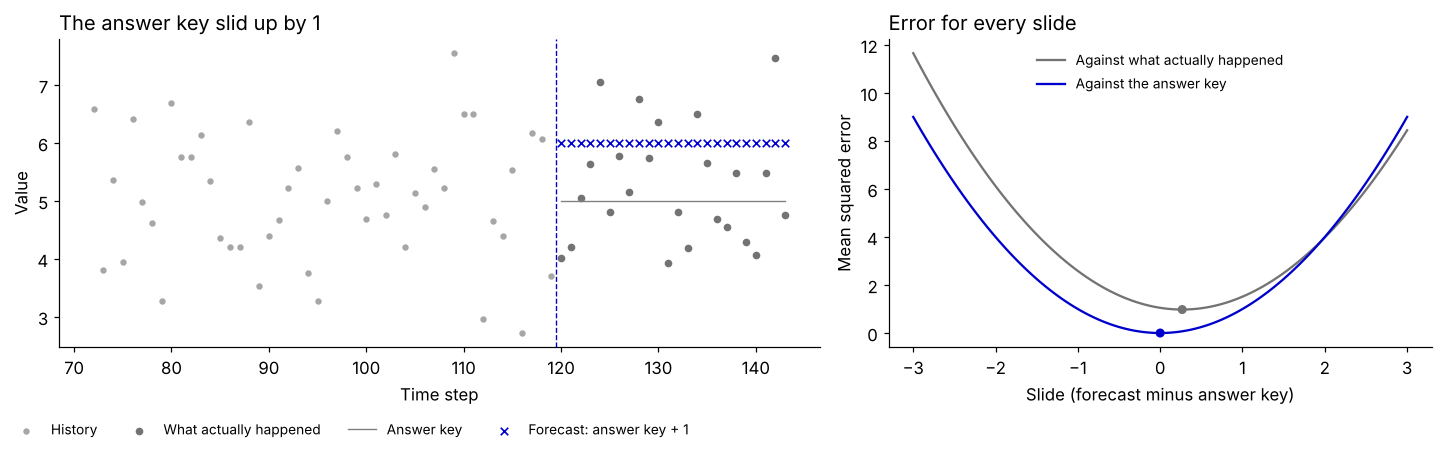

Against what actually happened, the answer key scores 1.05; the lowest error, 0.98, belongs to the forecast slid by +0.27, the average of this future's noise.


In [29]:
level = Scenario('white_noise', context_length=120, horizon=24,
                 parameters={'mean': 5., 'sigma': 1.}).generate(seed=3)
key, happened = level.reference.mean, level.observed.to_numpy()
slides = np.linspace(-3, 3, 121)
against_key = [mean_reference_mse(key, key + slide) for slide in slides]
against_happened = [mse(happened, key + slide) for slide in slides]
best = float((happened - key).mean())  # the slide that minimizes error against what happened

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4), layout='constrained', width_ratios=[1.4, 1])
past = level.task.context.iloc[-48:, 0]
left.scatter(past.index, past, s=10, color='0.65', label='History')
left.scatter(level.observed.index, happened[:, 0], s=16, color='0.45', label='What actually happened')
left.plot(level.reference.index, key[:, 0], color='0.5', lw=0.9, label='Answer key')
left.scatter(level.reference.index, key[:, 0] + 1, marker='x', s=24, linewidths=1.1, color='#0000CC',
             label='Forecast: answer key + 1', zorder=4)
left.axvline(level.reference.index[0] - 0.5, color='#0000CC', ls='--', lw=0.9)
left.set(title='The answer key slid up by 1', xlabel='Time step', ylabel='Value')
fig.legend(*left.get_legend_handles_labels(), loc='outside lower left', ncol=4, fontsize=9)
right.plot(slides, against_happened, color='0.45', lw=1.5, label='Against what actually happened')
right.plot(slides, against_key, color='#0000CC', lw=1.5, label='Against the answer key')
right.scatter([best, 0], [mse(happened, key + best), 0], color=['0.45', '#0000CC'], s=24, zorder=3)
right.set(title='Error for every slide', xlabel='Slide (forecast minus answer key)', ylabel='Mean squared error')
right.legend(loc='upper center', fontsize=9)
plt.show()

print(f"Against what actually happened, the answer key scores {mse(happened, key):.2f}; the lowest error, "
      f"{mse(happened, key + best):.2f}, belongs to the forecast slid by {best:+.2f}, "
      "the average of this future's noise.")
assert mse(happened, key + best) < mse(happened, key)  # a wrong forecast beats the answer key on this future

Against the answer key (blue), the error is 0 with no slide and grows with the square of the slide, whatever the noise did: slid by 1, the forecast scores exactly 1. Against what actually happened (gray), the curve sits about 1 higher near the middle, the noise no forecast can remove, and it tilts so that its lowest point lands on the average of this future's noise. A forecast that is wrong by a quarter beats the answer key, and with another future the lowest point would land somewhere else. That luck is what comparing with the answer key removes.

It matters most when you compare two models. Here the last value and the historical mean forecast 40 cases of mean reversion. The answer key starts at the last value and decays toward the long-run level, where the historical mean sits, so the mean should usually win over 12 steps. For each case we take the last value's error minus the historical mean's: a positive gain means the mean did better. `paired_t_interval` gives a 95% interval for the average gain, and `wilson_interval` one for the share of cases the mean wins:

In [30]:
gains = {'Error against what actually happened': [], 'Error against the answer key': []}
for seed in range(40):
    draw = mean_reversion.generate(seed=seed)
    last, average = (NaiveForecaster(strategy).fit(draw.task.context).predict(draw.task.future_index).point
                     for strategy in ('last', 'mean'))
    outcome = draw.observed.to_numpy()
    gains['Error against what actually happened'].append(mse(outcome, last) - mse(outcome, average))
    gains['Error against the answer key'].append(mean_reference_mse(draw.reference.mean, last)
                                                 - mean_reference_mse(draw.reference.mean, average))

paired = {error: paired_t_interval(values) for error, values in gains.items()}
wins = {error: wilson_interval(np.asarray(values) > 0) for error, values in gains.items()}
display(pd.DataFrame({error: {
    'Average gain of the historical mean': f"{paired[error]['mean']:.2f}",
    '95% interval': f"{paired[error]['ci95'][0]:.2f} to {paired[error]['ci95'][1]:.2f}",
    'Cases the historical mean wins': f"{wins[error]['count']} of {wins[error]['n']}",
    '95% interval for that share': f"{wins[error]['ci95'][0]:.0%} to {wins[error]['ci95'][1]:.0%}",
} for error in gains}).T)

width = {error: np.diff(interval['ci95'])[0] for error, interval in paired.items()}
assert width['Error against what actually happened'] > 1.5 * width['Error against the answer key']  # less scatter
assert paired['Error against the answer key']['ci95'][0] > 0  # the answer key says the historical mean is better

,Average gain of the historical mean,95% interval,Cases the historical mean wins,95% interval for that share
Error against what actually happened,0.26,-0.87 to 1.39,23 of 40,42% to 71%
Error against the answer key,0.48,0.12 to 0.84,28 of 40,55% to 82%


Over enough cases both errors would agree on the average gain, because the noise in what actually happened averages out; with 40 cases they say 0.26 and 0.48. What differs is how much the gain scatters from case to case. Against what actually happened, the 95% interval runs from -0.87 to 1.39. It includes 0, so these 40 cases can't say which model is better, and the interval for the share of wins (42% to 71%) includes a coin flip's 50%. Against the answer key, the interval runs from 0.12 to 0.84, three times narrower, and lies above 0: the historical mean is the better forecast for this series. On generated data, the answer key settles a comparison with far fewer cases.

## What each verdict means

`Pipeline.test` runs `evaluate_forecast` on every case and keeps a finding for each check. Four forecasts for the first case show all five verdicts: the answer key's own forecast and the last value from above, the answer key's forecast with its quantiles reversed (one of the fault fixtures), and `None`, which is what a `predict` that forgot its `return` hands back.

In [31]:
candidates = {"Answer key's own forecast": answer_key, 'Last value': last_value,
              'Quantiles reversed': mutate_forecast(answer_key, 'quantile_crossing'), 'Returned nothing': None}
results = {name: evaluate_forecast(case, forecast) for name, forecast in candidates.items()}


def finding_row(name):
    # All output-check findings share one row.
    if name == 'forecast_contract' or name.startswith('contract_'):
        return 'Output checks'
    return name.replace('_', ' ').capitalize()


verdicts = pd.DataFrame({name: {finding_row(d.name): d.status for d in result.diagnostics}
                         for name, result in results.items()}).fillna('not run')
verdicts.loc['Scores recorded'] = [str(len(result.metrics)) for result in results.values()]
assert verdicts.loc['Output checks'].tolist() == ['PASS', 'PASS', 'FAIL', 'ERROR']  # a broken output fails, a crash errors
assert not results['Quantiles reversed'].metrics  # a broken forecast gets no scores
display(verdicts)

reversed_finding = results['Quantiles reversed'].diagnostics[0]
crash = results['Returned nothing'].diagnostics[0]
print(f"Quantiles reversed: {reversed_finding.message}")
print(f"Returned nothing: {crash.message} {crash.evidence['exception_type']}: {crash.evidence['exception_message']}")

,Answer key's own forecast,Last value,Quantiles reversed,Returned nothing
Output checks,PASS,PASS,FAIL,ERROR
Point accuracy,INCONCLUSIVE,INCONCLUSIVE,not run,not run
Quantile accuracy,INCONCLUSIVE,UNSUPPORTED,not run,not run
Interval coverage,INCONCLUSIVE,not run,not run,not run
Sample scores,INCONCLUSIVE,UNSUPPORTED,not run,not run
Scores recorded,11,4,0,0


Quantiles reversed: Predicted quantiles decrease as the probability level increases.
Returned nothing: Forecast contract validation raised an exception. AttributeError: 'NoneType' object has no attribute 'validate'


Each column is one forecast and each row one finding:

- **PASS**: passed. The first two forecasts pass the output checks: right dates, every target in order, right shape, finite values, quantiles in order.
- **FAIL**: broken output. Reversed quantiles fail the output checks and nothing else runs. A broken forecast gets no scores, so a bug can't hide behind a decent score.
- **INCONCLUSIVE**: scored, but no pass mark was set. Every accuracy finding ends here, because only you know how much error is too much.
- **UNSUPPORTED**: not checked: the forecast lacks what the check needs. The last value has no quantiles or samples, and with no band there is no coverage to report.
- **ERROR**: crashed. The finding keeps the exception and its traceback, and in `Pipeline.test` the other cases carry on.

Only FAIL and ERROR count as failures. INCONCLUSIVE and UNSUPPORTED are not failures, but they are not passes either; [10 · Reports and replay](10_reports_and_replay.ipynb) shows how a report counts them.

## What each check catches

Each fault fixture breaks a correct forecast in one known way. Here are all eight, applied to the answer key's forecast for a case with two series (so that their names can be swapped), with the covariance check turned on (`check_dependence=True`). The first row is the forecast left alone.

In [32]:
FAULTS = {
    'index_shift': 'Labels every step one step late',
    'target_swap': "Swaps the two series' names, not their values",
    'horizon_truncation': 'Drops the last step',
    'nonfinite_point': 'Puts a NaN in the first point forecast',
    'quantile_crossing': 'Reverses the order of the quantiles',
    'sample_axis_swap': 'Swaps the sample and step axes',
    'variance_shrink': 'Shrinks the spread to a quarter',
    'dependence_shuffle': "Shuffles each step's samples on their own",
}
assert tuple(FAULTS) == MUTATIONS  # every fault fixture is here
two_series = Scenario('ar1', context_length=120, horizon=12, n_targets=2).generate(seed=0)
correct = two_series.reference.forecast(n_samples=64, seed=1)


def what_the_checks_say(forecast):
    result = evaluate_forecast(two_series, forecast, check_dependence=True)
    found = {d.name: d.status for d in result.diagnostics}
    broken = [name.removeprefix('contract_') for name, status in found.items()
              if name.startswith('contract_') and status == 'FAIL']
    return {'output checks': f"FAIL ({', '.join(broken)})" if broken else found['forecast_contract'],
            'covariance check': found.get('reference_covariance', 'not run'),
            'scored': 'yes' if result.metrics else 'no'}


faults = pd.DataFrame({'No fault': {'what it does': 'Nothing', **what_the_checks_say(correct)}}
                      | {name: {'what it does': description, **what_the_checks_say(mutate_forecast(correct, name))}
                         for name, description in FAULTS.items()}).T
assert faults['output checks'].iloc[1:7].str.startswith('FAIL').all()  # six faults break the output
quiet_faults = ['variance_shrink', 'dependence_shuffle']
assert faults.loc[quiet_faults, 'covariance check'].eq('FAIL').all()  # only the covariance check sees the last two
repaired = mutate_forecast(correct, 'index_shift', enabled=False)
assert what_the_checks_say(repaired) == what_the_checks_say(correct)  # enabled=False leaves the fault out
faults

,what it does,output checks,covariance check,scored
No fault,Nothing,PASS,PASS,yes
index_shift,Labels every step one step late,FAIL (index_mismatch),not run,no
target_swap,"Swaps the two series' names, not their values",FAIL (target_mismatch),not run,no
horizon_truncation,Drops the last step,FAIL (index_mismatch),not run,no
nonfinite_point,Puts a NaN in the first point forecast,FAIL (nonfinite_point),not run,no
quantile_crossing,Reverses the order of the quantiles,FAIL (quantile_crossing),not run,no
sample_axis_swap,Swaps the sample and step axes,FAIL (sample_shape),not run,no
variance_shrink,Shrinks the spread to a quarter,PASS,FAIL,yes
dependence_shuffle,Shuffles each step's samples on their own,PASS,FAIL,yes


Six faults break the output, and the output checks fail each one before anything else runs: no scores and no covariance check. Dropping the last step fails as wrong dates, because the last requested date is missing. The last two faults leave a well-formed forecast with the right dates and the same point forecasts, so the output checks pass, and only the covariance check, which compares the samples with the answer key, notices them. With `enabled=False`, `mutate_forecast` leaves the fault out, and the forecast passes like the first row.

Those last two are the dangerous kind, because nothing looks broken. Here is what they do to the sample paths of the first case:

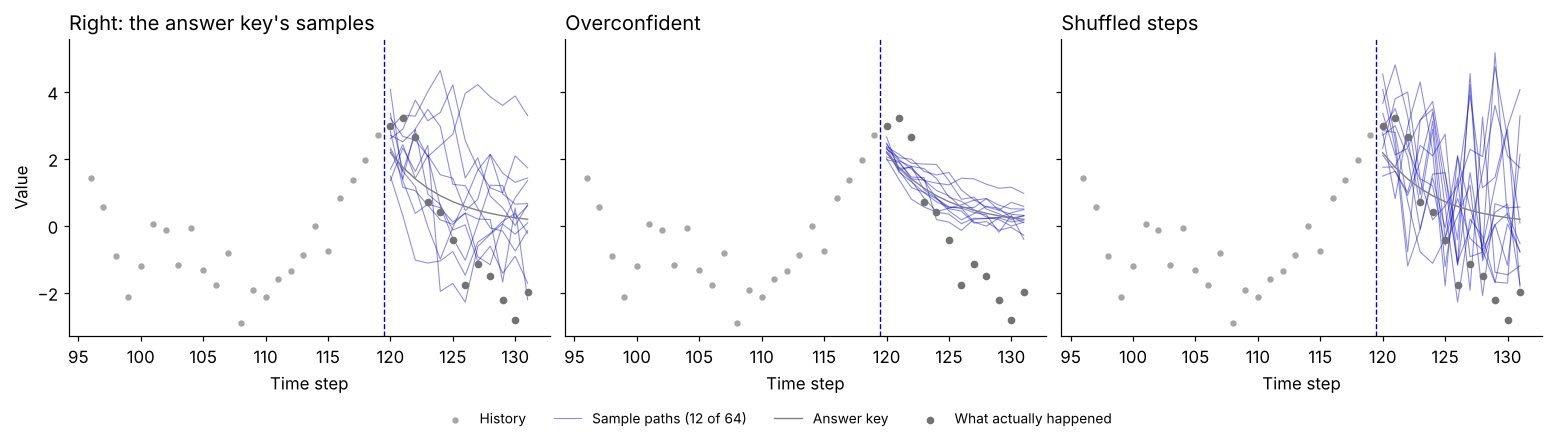

In [33]:
quiet = {"Right: the answer key's samples": answer_key,
         'Overconfident': mutate_forecast(answer_key, 'variance_shrink'),
         'Shuffled steps': mutate_forecast(answer_key, 'dependence_shuffle')}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True, layout='constrained')
past = case.task.context.iloc[-24:, 0]
for ax, (title, forecast) in zip(axes, quiet.items()):
    ax.scatter(past.index, past, s=10, color='0.65', label='History')
    ax.plot(forecast.index, forecast.samples[:12, :, 0].T, color='#0000CC', lw=0.7, alpha=0.45)
    ax.plot([], [], color='#0000CC', lw=0.7, alpha=0.45, label='Sample paths (12 of 64)')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.5', lw=0.9, label='Answer key')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=16, color='0.45', label='What actually happened',
               zorder=3)
    ax.axvline(forecast.index[0] - 0.5, color='#0000CC', ls='--', lw=0.9)
    ax.set(title=title, xlabel='Time step')
axes[0].set_ylabel('Value')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
plt.show()

The right paths wander, each one a plausible future. The overconfident ones keep a quarter of the spread and hug the answer key, and what actually happened falls outside them at most steps. The shuffled ones zigzag from step to step, yet at every step they hold exactly the same 64 values as the right ones, in a different order: a path that is high at one step is no longer likely to be high at the next.

Which scores notice? One case can't say, so we score all three forecasts on 40 cases of mean reversion and average. In brackets: in how many of the 40 cases the faulty forecast scored worse than the right one.

In [34]:
records = []
for seed in range(40):
    draw = mean_reversion.generate(seed=seed)
    right = draw.reference.forecast(n_samples=64, seed=seed)
    for name, forecast in {'Right': right, 'Overconfident': mutate_forecast(right, 'variance_shrink'),
                           'Shuffled steps': mutate_forecast(right, 'dependence_shuffle', seed=seed)}.items():
        result = evaluate_forecast(draw, forecast, check_dependence=True, dependence_seed=seed)
        finding = next(d for d in result.diagnostics if d.name == 'reference_covariance')
        records.append({'seed': seed, 'forecast': name, **result.metrics,
                        'covariance check fails': finding.status == 'FAIL'})
by_case = pd.DataFrame(records).pivot(index='seed', columns='forecast')


def summary(score, name):
    average = by_case[score][name].mean()
    if name == 'Right' or score == 'interval_coverage':
        return f'{average:.2f}'
    worse = int((by_case[score][name] > by_case[score]['Right'] + 1e-12).sum())
    return f'{average:.2f} (worse in {worse})'


QUIET_SCORES = ['mean_reference_mse', 'mse', 'pinball', 'crps', 'energy_score', 'variogram_score',
                'interval_coverage']
forecasts = ['Right', 'Overconfident', 'Shuffled steps']
quiet_table = pd.DataFrame({name: {SCORE_NAMES[score]: summary(score, name) for score in QUIET_SCORES}
                            for name in forecasts})
alarms = {name: wilson_interval(by_case['covariance check fails'][name].to_numpy()) for name in forecasts}
quiet_table.loc['Covariance check fails'] = [f"{alarm['count']} of {alarm['n']}" for alarm in alarms.values()]
assert (by_case['mse']['Overconfident'] == by_case['mse']['Right']).all()  # the point forecast doesn't move
crps_change = by_case['crps']['Shuffled steps'] - by_case['crps']['Right']
assert np.allclose(crps_change, 0, rtol=0, atol=1e-12)  # CRPS can't see the shuffle
display(quiet_table)
low, high = alarms['Right']['ci95']
print(f"The covariance check failed {alarms['Right']['count']} of the 40 right forecasts "
      f"({alarms['Right']['rate']:.0%}, 95% interval {low:.0%} to {high:.0%}).")

,Right,Overconfident,Shuffled steps
Error against the answer key,0.00,0.00 (worse in 0),0.00 (worse in 0)
Error against what actually happened,2.52,2.52 (worse in 0),2.52 (worse in 0)
Pinball loss (quantiles),0.39,0.53 (worse in 37),0.39 (worse in 0)
CRPS (each step on its own),0.91,1.10 (worse in 36),0.91 (worse in 0)
Energy score (whole paths),3.73,4.47 (worse in 37),3.81 (worse in 31)
Variogram score (pairs of steps),0.21,0.45 (worse in 38),0.25 (worse in 31)
Share inside the 10% to 90% band,0.79,0.22,0.79
Covariance check fails,2 of 40,40 of 40,40 of 40


The covariance check failed 2 of the 40 right forecasts (5%, 95% interval 1% to 17%).


Neither fault moves the point forecast, so both point errors are the same in every column. Pinball loss, CRPS and the band catch the overconfident forecast: its 10% to 90% band holds 22% of what actually happened instead of about 80%. The one-step scores can't see the shuffle at all: the quantiles are untouched and every step keeps its sample values, so pinball loss and CRPS come out exactly the same. Only the whole-path scores rise for the shuffled forecast, the energy score barely (3.81 against 3.73), and each scores it worse in only 31 of the 40 cases. The covariance check fails all 80 faulty forecasts, and 2 of the 40 right ones, the one in twenty it allows.

One case can mislead even about the overconfident forecast: on CRPS it beats the right forecast in 4 of the 40 cases. Judge uncertainty across many cases.

The last check needs no answer key at all, only a promise. Four forecasters get the first case's history, then the same history plus 10. The last value and the fitted AR(1) promise to move with the data. The other two don't keep that promise: one standardizes the history and forgets to scale its forecast back, which is a bug; the other decays the last value toward zero by a factor of 0.8 a step, which for this series is exactly the answer key's rule.

In [35]:
from timegym import GaussianAR1Forecaster, Pipeline


class ForgetsToScaleBack:
    """The last value of the standardized history, never scaled back: a bug."""

    def fit(self, context):
        self.last_ = ((context - context.mean()) / context.std()).iloc[-1]
        return self

    def predict(self, future_index):
        return pd.DataFrame([self.last_.to_numpy()] * len(future_index),
                            index=future_index, columns=self.last_.index)


class DecaysToZero:
    """The last value, decaying toward zero by 0.8 a step: the answer key's rule for this series."""

    def fit(self, context):
        self.last_ = context.iloc[-1]
        return self

    def predict(self, future_index):
        decay = 0.8 ** np.arange(1, len(future_index) + 1)[:, None]
        return pd.DataFrame(decay * self.last_.to_numpy(), index=future_index, columns=self.last_.index)


decay_forecast = DecaysToZero().fit(case.task.context).predict(case.task.future_index)
assert np.allclose(decay_forecast.to_numpy(), case.reference.mean)  # it is the answer key's own forecast

promises = {'Last value': NaiveForecaster('last'), 'Fitted AR(1)': GaussianAR1Forecaster(seed=0),
            'Forgets to scale back (a bug)': ForgetsToScaleBack, 'Decays to zero (the answer key)': DecaysToZero}
promise_checks = {name: check_shift_equivariance(Pipeline(model), case.task.context, case.task.future_index)
                  for name, model in promises.items()}
verdicts_after_shift = [check.status for check in promise_checks.values()]
assert verdicts_after_shift == ['PASS', 'PASS', 'FAIL', 'FAIL']  # a bug and a design choice both fail
pd.DataFrame({name: {'verdict': check.status,
                     'largest miss after adding 10': f"{check.evidence['max_absolute_error']:.2f}"}
              for name, check in promise_checks.items()}).T

,verdict,largest miss after adding 10
Last value,PASS,0.00
Fitted AR(1),PASS,0.00
Forgets to scale back (a bug),FAIL,10.00
Decays to zero (the answer key),FAIL,9.31


The last value and the fitted AR(1) move by exactly 10, to two decimals. The bug doesn't move at all, so it misses by the full 10. The decay rule misses by 9.31 at the last step, yet it is the best forecast there is for this series: it knows the long-run level is 0, so it shouldn't move with the history. The check can't tell a bug from a design choice. Run it on models that make the promise, and there a FAIL points to a bug without any answer key.

**Limits.** Accuracy has no pass mark: an INCONCLUSIVE score is a number for you to judge, and passing the output checks says a forecast is well formed, not that it is good. The error against the answer key exists only for generated data; on real data you have the error against what actually happened, and it needs more cases. The covariance check is a statistical test: a correct forecast fails it about one time in twenty, with no correction across cases, and its PASS means no difference was found, not that the spread is right. Intervals across cases need one value per independent case, never one per step. The fault fixtures break outputs, not code, and `enabled=False` is a repair you specify, not one TimeGym finds.

## Change one thing

- Raise the 40 cases in the comparison of the last value and the historical mean to 160: the error against what actually happened now tells the two apart as well, but its interval is still about twice as wide.
- Give the overconfident forecast `strength=0.2`, so it keeps 85% of the right spread: the covariance check now catches it in 9 of the 40 cases, and each score calls it worse in only about half of them.
- Then also pass `alpha=0.01` to `evaluate_forecast`: the check fails the right forecast once and the overconfident one once. A stricter test raises fewer false alarms and catches fewer real faults.

**Next:** [10 · Reports and replay](10_reports_and_replay.ipynb) collects these findings into a report you can gate a build on, save and replay. [Univariate uncertainty](../tutorials/08_univariate_uncertainty.ipynb) and [Faults, repairs and replay](../tutorials/03_faults_repairs_and_replay.ipynb) put the scores and fault fixtures to work on fitted models.